# 05 — Domain separability probe

Freeze a trained model, embed source and target crops, then train a classifier to tell which
domain each embedding came from. High accuracy = the two domains look different to that model.

This is the proxy A-distance, `PAD = 2(1 - 2*error)`, used in the DANN paper to show alignment
worked. Runs on both backbones.

**The test that matters is section 5.** We know `tuscaloosa` has *zero* performance gap while
`michael` and `matthew` have large ones. If separability is high everywhere including
tuscaloosa, then separability does not predict transfer, and the premise behind CORAL/DANN
does not hold for this data.

In [1]:
import sys, glob, warnings
from pathlib import Path

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

from src.config import load_config
from src.data.crops import CropDataset
from src.models.siamese import build_model
from src.domain_probe import run_probe, feature_gaps

N          = 4000       # samples per side; raise for tighter numbers, costs time
PROBE_KIND = "tree"     # "tree" (decision tree) or "mlp" (stronger, upper bound)
VAL_FRAC   = 0.5        # held-out share the probe is scored on
TREE_DEPTH = 8
PROBE_EPS  = 30         # mlp only
BATCH      = 256
SEED       = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print(ROOT, DEVICE)

/Users/_nltdzdbh_/Desktop/Desktop-icloud/McGill/Fall2026/ECSE552/final_project/Satellite-Disaster-Assessment-with-Domain-Adaptation mps


In [2]:
# what is available
for f in sorted(glob.glob(str(ROOT / "runs/*/*/best.pt"))):
    print(Path(f).parent.relative_to(ROOT))

runs/baseline/seed14_20261122-052243
runs/baseline/seed1_20261122-024216
runs/baseline/seed3_20261122-000109
runs/baseline_dinov2_ft2/seed14_20261124-050051
runs/baseline_dinov2_ft2/seed1_20261124-033047
runs/baseline_dinov2_ft2/seed3_20261124-020102
runs/baseline_frozen_dinov2/seed14_20261124-004738
runs/baseline_frozen_dinov2/seed1_20261123-233354
runs/baseline_frozen_dinov2/seed3_20261123-211531
runs/baseline_frozen_r34/seed3_20261123-225621
runs/bn_only/seed14_20261122-055030
runs/bn_only/seed1_20261122-030952
runs/bn_only/seed3_20261122-002908
runs/cdan/sanity
runs/cdan_dinov2_ft2/seed3_20261124-134724
runs/coral/seed14_20261122-062509
runs/coral/seed1_20261122-034429
runs/coral/seed3_20261122-010355
runs/coral_dinov2_ft2/seed3_20261124-083354
runs/dann/seed14_20261122-071409
runs/dann/seed1_20261122-043339
runs/dann/seed3_20261122-015310
runs/dann_dinov2_ft2/seed3_20261124-111037


## 1. Load a model, embed a split

In [3]:
def load_model(run_dir):
    cfg = load_config(run_dir / "config.yaml")
    cfg.model.pretrained = False                      # weights come from the checkpoint
    m = build_model(cfg).to(DEVICE)
    m.load_state_dict(torch.load(run_dir / "best.pt", map_location=DEVICE,
                                 weights_only=False)["model"])
    m.eval()
    return m, cfg


_ds = {}
def dataset(cfg, split):
    crops = Path(cfg.data.crops_dir)
    if not crops.is_absolute():
        crops = ROOT / crops                          # configs store it relative to the root
    key = (str(crops), split)
    if key not in _ds:
        _ds[key] = CropDataset(crops, split, train=False,
                               use_labels=True, max_black=cfg.data.max_black)
    return _ds[key]


@torch.no_grad()
def embed(model, cfg, split, event=None, n=N):
    """Bottleneck features z for n random crops of one split, optionally one event only."""
    ds = dataset(cfg, split)
    pool = np.arange(len(ds))
    if event is not None:
        pool = pool[ds.meta["event"].to_numpy() == event]
    if len(pool) == 0:
        return None
    idx = np.random.default_rng(SEED).choice(pool, size=min(n, len(pool)), replace=False)
    out = []
    for i in range(0, len(idx), BATCH):
        b = [ds[j] for j in idx[i:i + BATCH]]
        pre  = torch.stack([x["pre"]  for x in b]).to(DEVICE)
        post = torch.stack([x["post"] for x in b]).to(DEVICE)
        out.append(model.features(pre, post).float().cpu())
    return torch.cat(out)

## 2. The probe

Balance the two sides so chance is exactly 0.50, split, fit, score on the held-out half.

`tree` is a single decision tree, as proposed. `mlp` is the one in `src/domain_probe.py`.
A tree is weaker, so it gives a *lower bound* on separability and the MLP an upper bound - if
even the MLP sits at 0.50 the domains really are aligned. Running both is a fair robustness
check; just rerun the notebook with `PROBE_KIND` flipped.

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score


def run_probe_tree(z_a, z_b, seed=SEED, depth=TREE_DEPTH, val_frac=VAL_FRAC):
    n = min(len(z_a), len(z_b))
    g = np.random.default_rng(seed)
    x = np.concatenate([z_a[g.choice(len(z_a), n, replace=False)].numpy(),
                        z_b[g.choice(len(z_b), n, replace=False)].numpy()])
    y = np.concatenate([np.zeros(n), np.ones(n)])
    perm = g.permutation(len(x)); x, y = x[perm], y[perm]
    k = int(len(x) * val_frac)
    clf = DecisionTreeClassifier(max_depth=depth, random_state=seed).fit(x[k:], y[k:])
    return {"acc": float((clf.predict(x[:k]) == y[:k]).mean()),
            "auc": float(roc_auc_score(y[:k], clf.predict_proba(x[:k])[:, 1]))}


def probe(za, zb):
    r = (run_probe_tree(za, zb) if PROBE_KIND == "tree" else
         run_probe(za, zb, seed=SEED, epochs=PROBE_EPS, val_frac=VAL_FRAC, device=DEVICE))
    g = feature_gaps(za, zb)
    return {"n_side": min(len(za), len(zb)), "acc": r["acc"], "auc": r["auc"],
            "pad": 2 * (1 - 2 * (1 - r["acc"])), **g}


def verdict(a):
    return ("indistinguishable" if a < 0.60 else "barely separable" if a < 0.70 else
            "clearly separable" if a < 0.85 else "very different")

## 3. Runs to compare

In [5]:
WANT = {                      # label -> run group
    "resnet baseline":   "baseline",
    "resnet coral":      "coral",
    "resnet dann":       "dann",
    "dinov2 frozen":     "baseline_frozen_dinov2",
    "dinov2 ft2":        "baseline_dinov2_ft2",
    "dinov2 ft2 coral":  "coral_dinov2_ft2",
    "dinov2 ft2 dann":   "dann_dinov2_ft2",
    "dinov2 ft2 cdan":   "cdan_dinov2_ft2",
}
SEED_PICK = 3                 # probe one seed; all methods have seed 3

RUNS = {}
for label, group in WANT.items():
    hits = (sorted(glob.glob(str(ROOT / f"runs/{group}/seed{SEED_PICK}_*/best.pt")))
            or sorted(glob.glob(str(ROOT / f"runs/{group}/seed{SEED_PICK}/best.pt"))))
    if hits:
        RUNS[label] = Path(hits[-1]).parent          # newest if several timestamps
    else:
        print(f"skip {label:<20} (no seed{SEED_PICK} run in runs/{group}/)")

assert RUNS, "no runs found - check the group names in WANT against runs/"
RUNS

{'resnet baseline': PosixPath('/Users/_nltdzdbh_/Desktop/Desktop-icloud/McGill/Fall2026/ECSE552/final_project/Satellite-Disaster-Assessment-with-Domain-Adaptation/runs/baseline/seed3_20261122-000109'),
 'resnet coral': PosixPath('/Users/_nltdzdbh_/Desktop/Desktop-icloud/McGill/Fall2026/ECSE552/final_project/Satellite-Disaster-Assessment-with-Domain-Adaptation/runs/coral/seed3_20261122-010355'),
 'resnet dann': PosixPath('/Users/_nltdzdbh_/Desktop/Desktop-icloud/McGill/Fall2026/ECSE552/final_project/Satellite-Disaster-Assessment-with-Domain-Adaptation/runs/dann/seed3_20261122-015310'),
 'dinov2 frozen': PosixPath('/Users/_nltdzdbh_/Desktop/Desktop-icloud/McGill/Fall2026/ECSE552/final_project/Satellite-Disaster-Assessment-with-Domain-Adaptation/runs/baseline_frozen_dinov2/seed3_20261123-211531'),
 'dinov2 ft2': PosixPath('/Users/_nltdzdbh_/Desktop/Desktop-icloud/McGill/Fall2026/ECSE552/final_project/Satellite-Disaster-Assessment-with-Domain-Adaptation/runs/baseline_dinov2_ft2/seed3_20261

## 4. Aggregate probe

`source_train` against the whole target domain, and against the held-out caribbean split.

In [6]:
PAIRS = [("source_train", "target_train"), ("source_train", "test")]

rows = []
for label, run_dir in RUNS.items():
    model, cfg = load_model(run_dir)
    cache = {}
    def z(split):
        if split not in cache:
            cache[split] = embed(model, cfg, split)
        return cache[split]
    for a, b in PAIRS:
        rows.append({"run": label, "pair": f"{a} : {b}", **probe(z(a), z(b))})
        print(f"{label:<20}{a} : {b:<14}acc {rows[-1]['acc']:.3f}")
    del model, cache
    torch.mps.empty_cache() if DEVICE.type == "mps" else None

agg = pd.DataFrame(rows)
agg["verdict"] = agg["acc"].map(verdict)
agg.round(4)

resnet baseline     source_train : target_train  acc 0.750
resnet baseline     source_train : test          acc 0.910
resnet coral        source_train : target_train  acc 0.706
resnet coral        source_train : test          acc 0.896
resnet dann         source_train : target_train  acc 0.716
resnet dann         source_train : test          acc 0.903
dinov2 frozen       source_train : target_train  acc 0.789
dinov2 frozen       source_train : test          acc 0.890
dinov2 ft2          source_train : target_train  acc 0.766
dinov2 ft2          source_train : test          acc 0.901
dinov2 ft2 coral    source_train : target_train  acc 0.739
dinov2 ft2 coral    source_train : test          acc 0.868
dinov2 ft2 dann     source_train : target_train  acc 0.730
dinov2 ft2 dann     source_train : test          acc 0.883
dinov2 ft2 cdan     source_train : target_train  acc 0.649
dinov2 ft2 cdan     source_train : test          acc 0.857


,run,pair,n_side,acc,auc,pad,mean_gap,coral_dist,verdict
0,resnet baseline,source_train : target_train,4000,0.7498,0.7648,0.999,0.2759,0.1799,clearly separable
1,resnet baseline,source_train : test,4000,0.9100,0.8972,1.640,0.6257,0.1687,very different
2,resnet coral,source_train : target_train,4000,0.7058,0.7469,0.823,0.2777,0.0008,clearly separable
3,resnet coral,source_train : test,4000,0.8958,0.8990,1.583,0.5440,0.0010,very different
4,resnet dann,source_train : target_train,4000,0.7158,0.7507,0.863,0.2962,29.0978,clearly separable
5,resnet dann,source_train : test,4000,0.9030,0.8916,1.612,0.4479,23.6040,very different
6,dinov2 frozen,source_train : target_train,4000,0.7895,0.8070,1.158,0.2947,0.0592,clearly separable
7,dinov2 frozen,source_train : test,4000,0.8898,0.8843,1.559,0.5863,0.0835,very different
8,dinov2 ft2,source_train : target_train,4000,0.7665,0.7801,1.066,0.2721,0.4380,clearly separable
9,dinov2 ft2,source_train : test,4000,0.9015,0.9068,1.606,0.6017,0.7004,very different


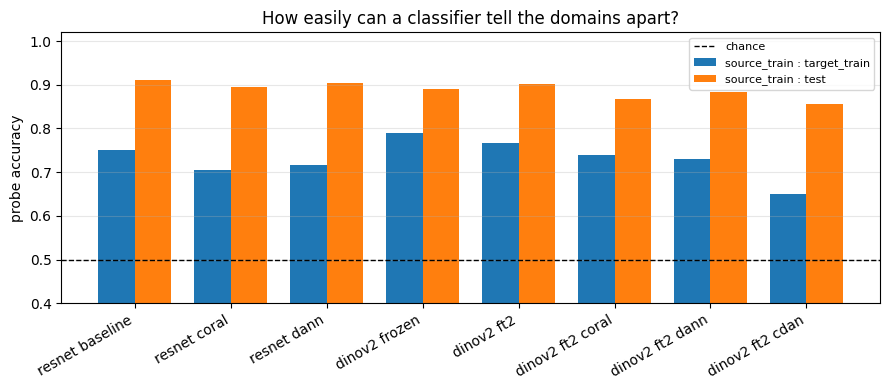

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
w, labels = 0.38, list(RUNS)
for i, (pair, g) in enumerate(agg.groupby("pair")):
    g = g.set_index("run").reindex(labels)
    ax.bar(np.arange(len(labels)) + i * w, g["acc"], w, label=pair)
ax.axhline(0.5, color="k", ls="--", lw=1, label="chance")
ax.set_xticks(np.arange(len(labels)) + w / 2)
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_ylabel("probe accuracy"); ax.set_ylim(0.4, 1.02)
ax.set_title("How easily can a classifier tell the domains apart?")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 5. Per-event probe — the key test

| pair | known performance gap |
|---|---|
| source vs tuscaloosa (us-south, tornado) | **+0.001, none** |
| source vs michael (us-south, hurricane) | −0.267 |
| source vs matthew (caribbean, hurricane) | −0.229 further |

If separability tracks the gap, the DA premise holds and the methods simply failed to align.
If tuscaloosa is just as separable as the others, separability does **not** predict transfer.

In [8]:
EVENTS = [("target_test", "tuscaloosa-tornado"),
          ("target_test", "hurricane-michael"),
          ("test",        "hurricane-matthew")]
# ResNet-34 baseline macro-F1 minus source_val, per event. DINOv2 gaps differ in size but
# the ordering is the same, so this is only the x-axis of the plot below.
GAP = {"tuscaloosa-tornado": 0.0012, "hurricane-michael": -0.2659, "hurricane-matthew": -0.4948}

rows = []
for label, run_dir in RUNS.items():
    model, cfg = load_model(run_dir)
    zs = embed(model, cfg, "source_train")
    for split, ev in EVENTS:
        ze = embed(model, cfg, split, event=ev)
        if ze is None:
            print(f"  {ev} not found in {split}"); continue
        rows.append({"run": label, "event": ev, "gap_vs_source": GAP[ev],
                     **probe(zs, ze)})
        print(f"{label:<20}{ev:<22}acc {rows[-1]['acc']:.3f}")
    del model, zs
    torch.mps.empty_cache() if DEVICE.type == "mps" else None

ev_df = pd.DataFrame(rows)
ev_df["verdict"] = ev_df["acc"].map(verdict)
ev_df.round(4)

resnet baseline     tuscaloosa-tornado    acc 0.707
resnet baseline     hurricane-michael     acc 0.772
resnet baseline     hurricane-matthew     acc 0.910
resnet coral        tuscaloosa-tornado    acc 0.664
resnet coral        hurricane-michael     acc 0.760
resnet coral        hurricane-matthew     acc 0.896
resnet dann         tuscaloosa-tornado    acc 0.715
resnet dann         hurricane-michael     acc 0.785
resnet dann         hurricane-matthew     acc 0.903
dinov2 frozen       tuscaloosa-tornado    acc 0.745
dinov2 frozen       hurricane-michael     acc 0.829
dinov2 frozen       hurricane-matthew     acc 0.890
dinov2 ft2          tuscaloosa-tornado    acc 0.757
dinov2 ft2          hurricane-michael     acc 0.822
dinov2 ft2          hurricane-matthew     acc 0.901
dinov2 ft2 coral    tuscaloosa-tornado    acc 0.692
dinov2 ft2 coral    hurricane-michael     acc 0.776
dinov2 ft2 coral    hurricane-matthew     acc 0.868
dinov2 ft2 dann     tuscaloosa-tornado    acc 0.728
dinov2 ft2 d

,run,event,gap_vs_source,n_side,acc,auc,pad,mean_gap,coral_dist,verdict
0,resnet baseline,tuscaloosa-tornado,0.0012,2481,0.7074,0.7171,0.8295,0.1612,0.0433,clearly separable
1,resnet baseline,hurricane-michael,-0.2659,4000,0.7720,0.8055,1.0880,0.3375,0.2435,clearly separable
2,resnet baseline,hurricane-matthew,-0.4948,4000,0.9100,0.8972,1.6400,0.6257,0.1687,very different
3,resnet coral,tuscaloosa-tornado,0.0012,2481,0.6642,0.6711,0.6570,0.1246,0.0003,barely separable
4,resnet coral,hurricane-michael,-0.2659,4000,0.7605,0.7940,1.0420,0.3541,0.0011,clearly separable
5,resnet coral,hurricane-matthew,-0.4948,4000,0.8958,0.8990,1.5830,0.5440,0.0010,very different
6,resnet dann,tuscaloosa-tornado,0.0012,2481,0.7154,0.7507,0.8617,0.1251,6.8093,clearly separable
7,resnet dann,hurricane-michael,-0.2659,4000,0.7852,0.8005,1.1410,0.3655,39.3393,clearly separable
8,resnet dann,hurricane-matthew,-0.4948,4000,0.9030,0.8916,1.6120,0.4479,23.6040,very different
9,dinov2 frozen,tuscaloosa-tornado,0.0012,2481,0.7449,0.7350,0.9794,0.2157,0.0350,clearly separable


In [9]:
piv = ev_df.pivot(index="run", columns="event", values="acc").reindex(list(RUNS))
piv = piv[[e for _, e in EVENTS]]
print("probe accuracy by event (0.50 = chance)\n")
print(piv.round(3).to_string())

print("\nperformance gap vs source_val, for comparison")
print(pd.Series(GAP).round(4).to_string())

probe accuracy by event (0.50 = chance)

event             tuscaloosa-tornado  hurricane-michael  hurricane-matthew
run                                                                       
resnet baseline                0.707              0.772              0.910
resnet coral                   0.664              0.760              0.896
resnet dann                    0.715              0.785              0.903
dinov2 frozen                  0.745              0.829              0.890
dinov2 ft2                     0.757              0.822              0.902
dinov2 ft2 coral               0.692              0.776              0.868
dinov2 ft2 dann                0.728              0.783              0.883
dinov2 ft2 cdan                0.704              0.705              0.857

performance gap vs source_val, for comparison
tuscaloosa-tornado    0.0012
hurricane-michael    -0.2659
hurricane-matthew    -0.4948


## 6. Separability against the performance gap

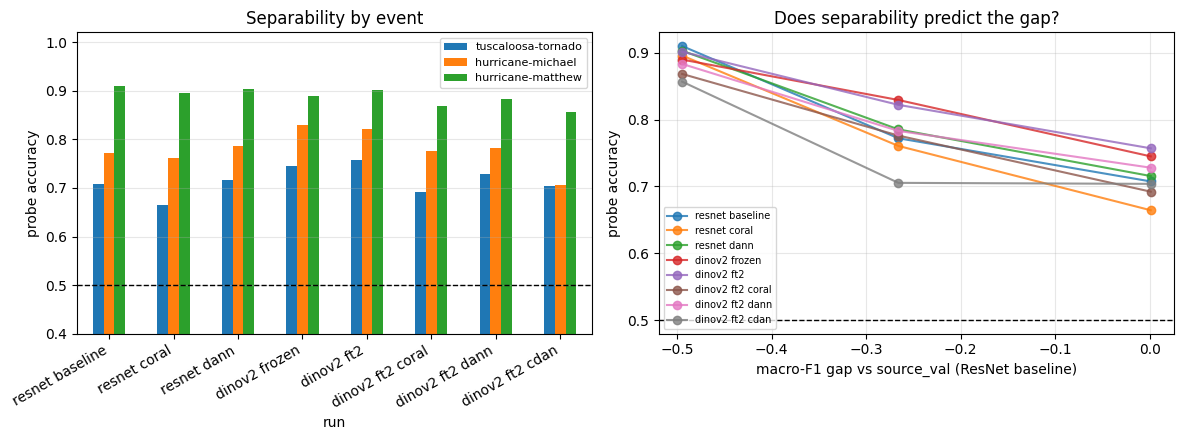

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

piv.plot(kind="bar", ax=axes[0], rot=30)
axes[0].axhline(0.5, color="k", ls="--", lw=1)
axes[0].set_ylabel("probe accuracy"); axes[0].set_ylim(0.4, 1.02)
axes[0].set_title("Separability by event")
axes[0].legend(fontsize=8); axes[0].grid(axis="y", alpha=.3)
for lab in axes[0].get_xticklabels():
    lab.set_ha("right")

for label in piv.index:
    axes[1].plot([GAP[e] for e in piv.columns], piv.loc[label], "o-", label=label, alpha=.8)
axes[1].axhline(0.5, color="k", ls="--", lw=1)
axes[1].set_xlabel("macro-F1 gap vs source_val (ResNet baseline)"); axes[1].set_ylabel("probe accuracy")
axes[1].set_title("Does separability predict the gap?")
axes[1].legend(fontsize=7); axes[1].grid(alpha=.3)

plt.tight_layout(); plt.show()

## 7. t-SNE of the embeddings

A picture of what section 4 measures. Each point is one building's `z`, coloured by domain.

t-SNE is a visualisation, not a measurement. Cluster sizes, distances and empty space are
artefacts; only local neighbourhoods mean anything. Believe the probe number, not the picture.

done resnet baseline
done resnet coral
done resnet dann
done dinov2 frozen
done dinov2 ft2
done dinov2 ft2 coral
done dinov2 ft2 dann
done dinov2 ft2 cdan


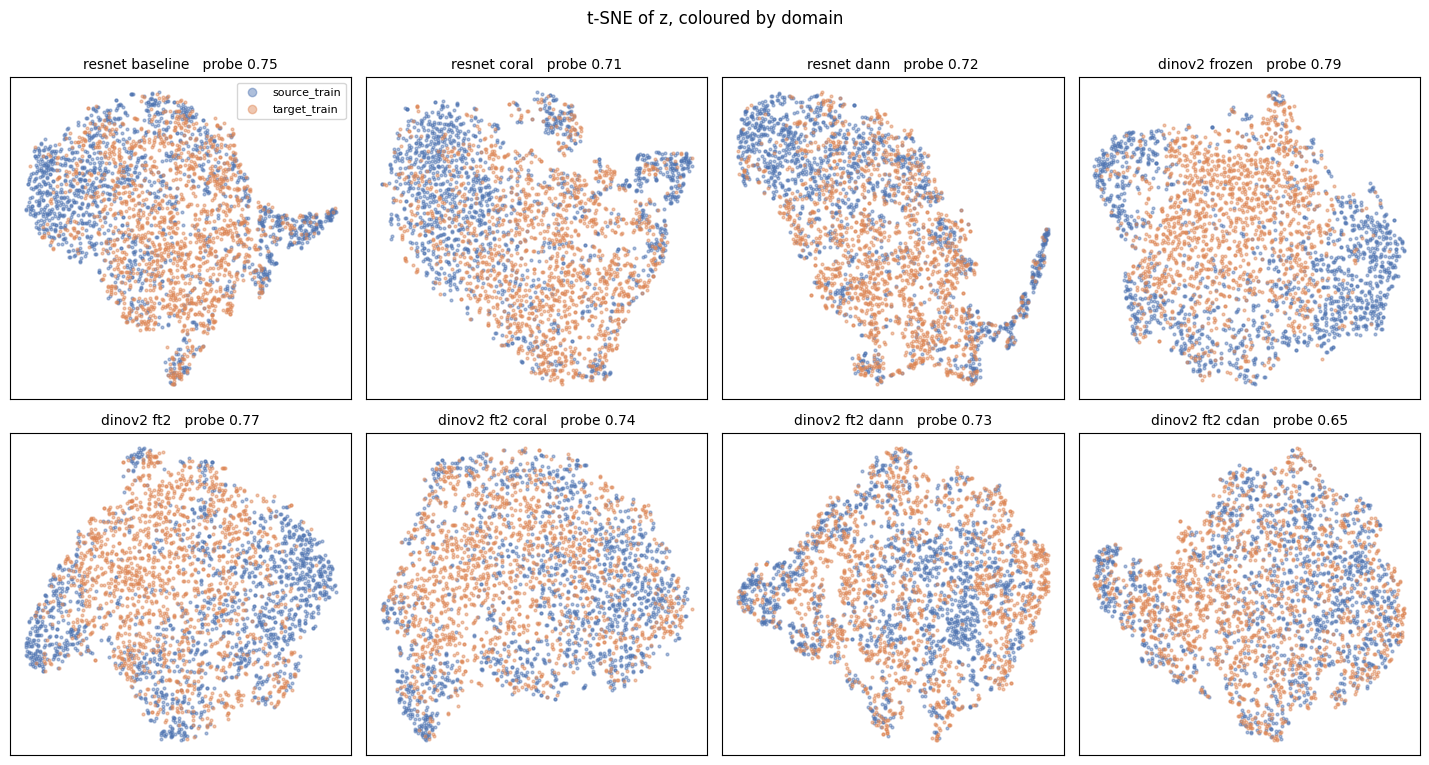

In [11]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

TSNE_SPLITS = ["source_train", "target_train"]   # add "test" for a three-way plot
TSNE_N      = 1500                               # points per split
TSNE_PERP   = 30
PALETTE     = ["#4C72B0", "#DD8452", "#55A868"]


def tsne_xy(zs, seed=SEED):
    """One t-SNE over all splits together, so the domains share a space."""
    x = np.concatenate([z.numpy() for z in zs])
    x = PCA(n_components=min(50, x.shape[1]), random_state=seed).fit_transform(x)
    return TSNE(n_components=2, perplexity=TSNE_PERP, init="pca",
                random_state=seed).fit_transform(x)


cols = min(4, len(RUNS))
nrow = int(np.ceil(len(RUNS) / cols))
fig, axes = plt.subplots(nrow, cols, figsize=(3.6 * cols, 3.8 * nrow), squeeze=False)

for k, (label, run_dir) in enumerate(RUNS.items()):
    model, cfg = load_model(run_dir)
    zs = [embed(model, cfg, sp, n=TSNE_N) for sp in TSNE_SPLITS]
    xy = tsne_xy(zs)

    ax, i = axes[k // cols][k % cols], 0
    for sp, z, c in zip(TSNE_SPLITS, zs, PALETTE):
        ax.scatter(xy[i:i + len(z), 0], xy[i:i + len(z), 1], s=4, alpha=.45, c=c, label=sp)
        i += len(z)

    hit = agg[(agg["run"] == label) & (agg["pair"] == "source_train : target_train")]["acc"]
    ax.set_title(label + (f"   probe {hit.iloc[0]:.2f}" if len(hit) else ""), fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    if k == 0:
        ax.legend(fontsize=8, markerscale=3, loc="best")
    print(f"done {label}")
    del model, zs

for j in range(len(RUNS), nrow * cols):
    axes[j // cols][j % cols].axis("off")
fig.suptitle("t-SNE of z, coloured by domain", y=1.0)
plt.tight_layout(); plt.show()

## 7. How to read it

**Flat line in the right-hand plot** — separability is the same whether the gap is 0 or −0.50.
Then a classifier telling the domains apart says nothing about whether the model transfers, and
minimising that separability (what DANN and CORAL do) is optimising the wrong thing. This would
explain the negative results directly.

**Rising line** — separability tracks the gap. Then alignment is the right target and our
methods simply failed to achieve it, which the small baseline→CORAL/DANN movements already
suggest.

Also worth checking in the tables:

- `mean_gap` vs `coral_dist`. CORAL's loss contains no mean term, so a CORAL run should drop
  `coral_dist` and leave `mean_gap` roughly unchanged. If both drop, something else moved them.
- DINOv2 vs ResNet on `source_train : test`. DINOv2 cut the caribbean performance gap in half;
  if its features are also less separable there, the two agree.
- `acc` vs `auc`. A big gap between them means the probe is unbalanced somewhere.